In [27]:
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader

# 1. Data Preparation and Loading

In [28]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [29]:
train_dataset = CIFAR10(
    root="./data",
    train=True, 
    download=True,
    transform=transform
)

In [30]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True
)

In [31]:
print(f"Número de imágenes: {len(train_dataset)}")
print(f"Número de clases: {len(train_dataset.classes)}")
print(f"Clases: {train_dataset.classes}")

Número de imágenes: 50000
Número de clases: 10
Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [32]:
# Verify that the images are normalized correctly
real_images, labels = next(iter(train_loader))

print(real_images.shape)
print(real_images.min())
print(real_images.max())

torch.Size([64, 3, 32, 32])
tensor(-1.)
tensor(1.)


# 2. Model Architecture
## 2.1 Latent space

In [33]:
z_dim = 128

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

z = torch.randn(batch_size, z_dim, device=device)

In [34]:
print(z.shape)

torch.Size([64, 128])


## 2.2 Generator

In [35]:
class Generator(nn.Module):
    def __init__(self, latent_dim=128, dim=128):
        super().__init__()

        self.latent_dim = latent_dim
        self.dim = dim

        self.linear =  nn.Linear(latent_dim, 4 * 4 * 4 * dim)

        self.bn1 = nn.BatchNorm1d(4 * 4 * 4 * dim)

        self.deconv1 = nn.ConvTranspose2d(4 * dim, 2 * dim, kernel_size=5, stride=2, padding=2, output_padding=1)

        self.bn2 = nn.BatchNorm2d(2 * dim)

        self.deconv2 = nn.ConvTranspose2d(2 * dim, dim, kernel_size=5, stride=2, padding=2, output_padding=1)

        self.bn3 = nn.BatchNorm2d(dim)

        self.deconv3 = nn.ConvTranspose2d(dim, 3, kernel_size=5, stride=2, padding=2, output_padding=1)

        self.relu = nn.ReLU()

        self.tanh = nn.Tanh()

    def forward(self, z):
        # Linear transformation
        x = self.linear(z)

        # Batch normalization + ReLU activation
        x = self.bn1(x)
        x = self.relu(x)

        # Reshape into a 4x4 feature map
        x = x.view(-1, 4 * self.dim, 4, 4)

        # 4x4 -> 8x8
        x = self.deconv1(x)
        x = self.bn2(x)
        x = self.relu(x)

        # 8x8 -> 16x16
        x = self.deconv2(x)
        x = self.bn3(x)
        x = self.relu(x)

        # 16x16 -> 32x32
        x = self.deconv3(x)

        # Output activation
        x = self.tanh(x)

        return x

## 2.3 Critic

In [36]:
class Critic(nn.Module):
    def __init__(self, dim=128):
        super().__init__()

        self.dim = dim

        self.conv1 = nn.Conv2d(3, dim, kernel_size=5, stride=2, padding=2)

        self.leaky_relu = nn.LeakyReLU(0.2)

        self.conv2 = nn.Conv2d(dim, 2 * dim, kernel_size=5, stride=2, padding=2)

        self.bn2 = nn.BatchNorm2d(2 * dim)

        self.conv3 = nn.Conv2d(2 * dim, 4 * dim, kernel_size=5, stride=2, padding=2)

        self.bn3 = nn.BatchNorm2d(4 * dim)

        self.linear = nn.Linear(4 * 4 * 4 * dim, 1)

    def forward(self, x):
        # 32x32 -> 16x16
        x = self.conv1(x)
        x = self.leaky_relu(x)

        # 16x16 -> 8x8
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.leaky_relu(x)

        # 8x8 -> 4x4
        x = self.conv3(x)
        x = self.bn3(x)
        x = self.leaky_relu(x)

        # Flatten
        x = x.view(-1, 4 * 4 * 4 * self.dim)

        # Linear transformation
        x = self.linear(x)

        return x

# 3. WGAN

In [37]:
def train_critic(generator, critic, real_images, optimizer_D, z_dim, device):
    batch_size = real_images.size(0)

    # Generate fake images
    z = torch.randn(batch_size, z_dim, device=device)
    fake_images = generator(z)

    # Compute Wasserstein loss
    real_scores = critic(real_images)
    fake_scores = critic(fake_images.detach())
    critic_loss = torch.mean(fake_scores) - torch.mean(real_scores)

    # Update critic parameters
    optimizer_D.zero_grad()
    critic_loss.backward()
    optimizer_D.step()

    # Weight clipping
    for p in critic.parameters():
        p.data.clamp_(-0.01, 0.01)

    return critic_loss.item()

def train_generator(generator, critic, optimizer_G, batch_size, z_dim, device):
    z = torch.randn(batch_size, z_dim, device=device)

    fake_images = generator(z)

    # Compute generator loss
    fake_scores = critic(fake_images)
    generator_loss = -torch.mean(fake_scores)

    # Update generator parameters
    optimizer_G.zero_grad()
    generator_loss.backward()
    optimizer_G.step()

    return generator_loss.item()

from itertools import cycle

CRITIC_ITERATIONS = 5
N_ITERATIONS = 1000 #200000

generator = Generator(latent_dim=z_dim, dim=128).to(device)
critic = Critic(dim=128).to(device)

optimizer_G = torch.optim.RMSprop(generator.parameters(), lr=5e-5)
optimizer_D = torch.optim.RMSprop(critic.parameters(), lr=5e-5)

train_iterator = cycle(train_loader)

generator_losses = []
critic_losses = []

for iteration in range(N_ITERATIONS):
    for _ in range(CRITIC_ITERATIONS):
        real_images, _ = next(train_iterator)
        real_images = real_images.to(device)

        critic_loss = train_critic(generator, critic, real_images, optimizer_D, z_dim, device)
        critic_losses.append(critic_loss)

    generator_loss = train_generator(generator, critic, optimizer_G, batch_size, z_dim, device)
    generator_losses.append(generator_loss)

    if iteration % 100 == 0:
        print(f"Iteration {iteration}: Critic Loss: {critic_loss:.4f}, Generator Loss: {generator_loss:.4f}")

import matplotlib.pyplot as plt

generator.eval()

with torch.no_grad():
    z = torch.randn(64, z_dim, device=device)
    generated_images = generator(z)

generator.train()

generated_images = (generated_images + 1) / 2 # Rescale to [0, 1]

fig, axes = plt.subplots(8, 8, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    image = generated_images[i].cpu().permute(1, 2, 0)

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 4. WGAN-GP

In [38]:
# ==============================================================
# 4. WGAN-GP
# ==============================================================

import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from itertools import cycle

In [39]:
class CriticGP(nn.Module):
    def __init__(self, dim=128):
        super().__init__()

        self.dim = dim
        
        # 32x32 -> 16x16
        self.conv1 = nn.Conv2d(3, dim, kernel_size=5, stride=2, padding=2)
        # 16x16 -> 8x8
        self.conv2 = nn.Conv2d(dim, 2 * dim, kernel_size=5, stride=2, padding=2)
        # 8x8 -> 4x4
        self.conv3 = nn.Conv2d(2 * dim, 4 * dim, kernel_size=5, stride=2, padding=2)
        # 4*dim channels x 4 x 4 -> scalar critic score
        self.linear = nn.Linear(4 * 4 * 4 * dim, 1)
        
        self.leaky_relu = nn.LeakyReLU(0.2)

    def forward(self, x):
        # 32x32 -> 16x16
        x = self.conv1(x)
        x = self.leaky_relu(x)

        # 16x16 -> 8x8
        x = self.conv2(x)
        x = self.leaky_relu(x)

        # 8x8 -> 4x4
        x = self.conv3(x)
        x = self.leaky_relu(x)

        # Flatten
        x = x.view(-1, 4 * 4 * 4 * self.dim)

        # Linear transformation
        x = self.linear(x)

        return x
    
# Se ha quitado BatchNorm porque esto hace que cada muestra dependa de las demas muestras del batch
# Y WGAN-GP, la penalizacion de gradiente se calcula para cada muestra individual por lo que se tiene que quitar sino estropea la interpretacion de la gradient penalty

## 4.1 Interpolation

In [40]:
def interpolate_samples(real_images, fake_images):
    """
    Creates random interpolations between real and generated images.

    Args:
        real_images: Tensor of real images with shape (B, C, H, W).
        fake_images: Tensor of generated images with shape (B, C, H, W).

    Returns:
        interpolated_images: Tensor with shape (B, C, H, W).
    """

    batch_size = real_images.size(0)

    alpha = torch.rand(batch_size, 1, 1, 1, device=real_images.device)
    differences = fake_images - real_images
    interpolated_images = real_images + (alpha * differences)
    return interpolated_images

## 4.2 Gradient penalty


In [41]:
def gradient_penalty(critic, interpolated_images):
    """
    Computes the gradient penalty for WGAN-GP.

    Args:
        critic: WGAN-GP critic network.
        interpolated_images: Tensor of interpolated images
                             with shape (B, C, H, W).

    Returns:
        gradient_penalty: Scalar gradient penalty.
    """

    interpolated_images = interpolated_images.detach().requires_grad_(True)

    interpolated_scores = critic(interpolated_images)

    gradients = torch.autograd.grad(
        outputs=interpolated_scores,
        inputs=interpolated_images,
        grad_outputs=torch.ones_like(interpolated_scores),
        create_graph=True,
        retain_graph=True
    )[0]

    # (B, C, H, W) -> (B, C*H*W)
    gradients = gradients.reshape(gradients.size(0), -1)

    # Compute the L2 norm of the gradient for each image
    slopes = gradients.norm(2, dim=1)

    # Gradient penalty
    gradient_penalty = ((slopes - 1.0) ** 2).mean()

    return gradient_penalty

## 4.3 WGAN-GP critic loss

In [42]:
# ==============================================================
# 4.3 WGAN-GP CRITIC LOSS
# ==============================================================

def wgan_gp_critic_loss(
    critic,
    real_images,
    fake_images,
    lambda_gp=10.0
):

    # Critic scores
    real_scores = critic(
        real_images
    )

    fake_scores = critic(
        fake_images.detach()
    )

    # Same Wasserstein component as in WGAN
    wasserstein_loss = (
        fake_scores.mean()
        - real_scores.mean()
    )

    # Interpolated samples
    interpolated_images = interpolate_samples(
        real_images,
        fake_images.detach()
    )

    # Gradient penalty
    gp = gradient_penalty(
        critic,
        interpolated_images
    )

    # Total WGAN-GP critic loss
    critic_loss = (
        wasserstein_loss
        + lambda_gp * gp
    )

    return (
        critic_loss,
        wasserstein_loss,
        gp
    )

## 4.4 Training loop



In [43]:
# ==============================================================
# 4.4 TRAIN CRITIC
# ==============================================================

def train_critic_gp(
    generator,
    critic,
    real_images,
    optimizer_D,
    z_dim,
    device,
    lambda_gp=10.0
):

    batch_size_current = real_images.size(0)

    # Random latent vectors
    z = torch.randn(
        batch_size_current,
        z_dim,
        device=device
    )

    # Generate fake images
    # Generator is not updated during critic training
    with torch.no_grad():
        fake_images = generator(z)

    # WGAN-GP loss
    critic_loss, wasserstein_loss, gp = (
        wgan_gp_critic_loss(
            critic=critic,
            real_images=real_images,
            fake_images=fake_images,
            lambda_gp=lambda_gp
        )
    )

    # Update critic
    optimizer_D.zero_grad()

    critic_loss.backward()

    optimizer_D.step()

    # No weight clipping in WGAN-GP

    return (
        critic_loss.item(),
        wasserstein_loss.item(),
        gp.item()
    )

In [44]:
# ==============================================================
# 4.5 TRAIN GENERATOR
# ==============================================================

def train_generator_gp(
    generator,
    critic,
    optimizer_G,
    batch_size,
    z_dim,
    device
):

    # Random latent vectors
    z = torch.randn(
        batch_size,
        z_dim,
        device=device
    )

    # Generate fake images
    fake_images = generator(z)

    # Critic scores
    fake_scores = critic(
        fake_images
    )

    # Generator Wasserstein loss
    generator_loss = (
        -fake_scores.mean()
    )

    # Update generator
    optimizer_G.zero_grad()

    generator_loss.backward()

    optimizer_G.step()

    return generator_loss.item()

In [45]:
# ==============================================================
# 4.6 TRAINING CONFIGURATION
# ==============================================================

CRITIC_ITERATIONS_GP = 5

MAX_ITERATIONS_GP = 300000

LAMBDA_GP = 10.0

LEARNING_RATE_GP = 1e-4


# Permanent checkpoints used for comparisons
MILESTONES_GP = {
    1000,
    10000,
    100000,
    200000,
    300000
}


# Recovery checkpoint every 1000 iterations
SAVE_EVERY_GP = 1000


# Change this path if you want to save checkpoints
# in persistent storage
CHECKPOINT_DIR_GP = "checkpoints_wgan_gp"


os.makedirs(
    CHECKPOINT_DIR_GP,
    exist_ok=True
)


LATEST_CHECKPOINT_GP = os.path.join(
    CHECKPOINT_DIR_GP,
    "wgan_gp_latest.pt"
)

In [46]:
# ==============================================================
# 4.7 CREATE MODELS
# ==============================================================

generator_gp = Generator(
    latent_dim=z_dim,
    dim=128
).to(device)


critic_gp = CriticGP(
    dim=128
).to(device)

In [47]:
# ==============================================================
# 4.8 OPTIMIZERS
# ==============================================================

optimizer_G_gp = torch.optim.Adam(
    generator_gp.parameters(),
    lr=LEARNING_RATE_GP,
    betas=(0.5, 0.9)
)


optimizer_D_gp = torch.optim.Adam(
    critic_gp.parameters(),
    lr=LEARNING_RATE_GP,
    betas=(0.5, 0.9)
)

In [48]:
# ==============================================================
# 4.9 TRAINING RESULTS
# ==============================================================

# Generator loss
generator_losses_gp = []

# Total WGAN-GP critic loss
critic_losses_gp = []

# Wasserstein component
# This is the component comparable with the WGAN critic loss
wasserstein_losses_gp = []

# Gradient penalty
gradient_penalties_gp = []


# Fixed noise for later visual comparisons
fixed_noise_gp = torch.randn(
    64,
    z_dim,
    device=device
)

In [49]:
# ==============================================================
# 4.10 SAVE CHECKPOINT FUNCTION
# ==============================================================

def save_wgan_gp_checkpoint(
    path,
    iteration,
    generator,
    critic,
    optimizer_G,
    optimizer_D,
    generator_losses,
    critic_losses,
    wasserstein_losses,
    gradient_penalties,
    fixed_noise
):

    checkpoint = {

        # ------------------------------------------------------
        # Iteration
        # ------------------------------------------------------

        "iteration": iteration,


        # ------------------------------------------------------
        # Models
        # ------------------------------------------------------

        "generator_state_dict":
            generator.state_dict(),

        "critic_state_dict":
            critic.state_dict(),


        # ------------------------------------------------------
        # Optimizers
        # ------------------------------------------------------

        "optimizer_G_state_dict":
            optimizer_G.state_dict(),

        "optimizer_D_state_dict":
            optimizer_D.state_dict(),


        # ------------------------------------------------------
        # Training results
        # ------------------------------------------------------

        "generator_losses":
            generator_losses,

        "critic_losses":
            critic_losses,

        "wasserstein_losses":
            wasserstein_losses,

        "gradient_penalties":
            gradient_penalties,


        # ------------------------------------------------------
        # Fixed noise
        # ------------------------------------------------------

        "fixed_noise":
            fixed_noise.detach().cpu(),


        # ------------------------------------------------------
        # Configuration
        # ------------------------------------------------------

        "z_dim":
            z_dim,

        "dim":
            128,

        "lambda_gp":
            LAMBDA_GP,

        "critic_iterations":
            CRITIC_ITERATIONS_GP,

        "learning_rate":
            LEARNING_RATE_GP,

        "betas":
            (0.5, 0.9)
    }


    torch.save(
        checkpoint,
        path
    )

In [50]:
# ==============================================================
# 4.11 LOAD LATEST CHECKPOINT IF IT EXISTS
# ==============================================================

start_iteration_gp = 0


if os.path.exists(
    LATEST_CHECKPOINT_GP
):

    print(
        "Previous WGAN-GP checkpoint found."
    )


    checkpoint_gp = torch.load(
        LATEST_CHECKPOINT_GP,
        map_location=device
    )


    # ----------------------------------------------------------
    # Models
    # ----------------------------------------------------------

    generator_gp.load_state_dict(
        checkpoint_gp[
            "generator_state_dict"
        ]
    )


    critic_gp.load_state_dict(
        checkpoint_gp[
            "critic_state_dict"
        ]
    )


    # ----------------------------------------------------------
    # Optimizers
    # ----------------------------------------------------------

    optimizer_G_gp.load_state_dict(
        checkpoint_gp[
            "optimizer_G_state_dict"
        ]
    )


    optimizer_D_gp.load_state_dict(
        checkpoint_gp[
            "optimizer_D_state_dict"
        ]
    )


    # ----------------------------------------------------------
    # Training histories
    # ----------------------------------------------------------

    generator_losses_gp = checkpoint_gp[
        "generator_losses"
    ]


    critic_losses_gp = checkpoint_gp[
        "critic_losses"
    ]


    wasserstein_losses_gp = checkpoint_gp[
        "wasserstein_losses"
    ]


    gradient_penalties_gp = checkpoint_gp[
        "gradient_penalties"
    ]


    # ----------------------------------------------------------
    # Fixed noise
    # ----------------------------------------------------------

    fixed_noise_gp = checkpoint_gp[
        "fixed_noise"
    ].to(device)


    # ----------------------------------------------------------
    # Resume iteration
    # ----------------------------------------------------------

    start_iteration_gp = checkpoint_gp[
        "iteration"
    ]


    print(
        f"Training resumes from iteration "
        f"{start_iteration_gp}."
    )


else:

    print(
        "No previous checkpoint found. "
        "Training starts from iteration 0."
    )

Previous WGAN-GP checkpoint found.
Training resumes from iteration 22078.


In [51]:
# ==============================================================
# 4.12 DATA ITERATOR
# ==============================================================

train_iterator_gp = cycle(
    train_loader
)

In [52]:
# ==============================================================
# 4.13 TRAINING LOOP
# ==============================================================

completed_iteration_gp = start_iteration_gp


try:

    for iteration in range(
        start_iteration_gp,
        MAX_ITERATIONS_GP
    ):

        # ======================================================
        # 1. TRAIN CRITIC 5 TIMES
        # ======================================================

        for _ in range(
            CRITIC_ITERATIONS_GP
        ):

            # Real images
            real_images, _ = next(
                train_iterator_gp
            )

            real_images = real_images.to(
                device
            )


            # Train critic
            (
                critic_loss,
                wasserstein_loss,
                gp
            ) = train_critic_gp(

                generator=generator_gp,

                critic=critic_gp,

                real_images=real_images,

                optimizer_D=optimizer_D_gp,

                z_dim=z_dim,

                device=device,

                lambda_gp=LAMBDA_GP
            )


            # Save critic results
            critic_losses_gp.append(
                critic_loss
            )


            wasserstein_losses_gp.append(
                wasserstein_loss
            )


            gradient_penalties_gp.append(
                gp
            )


        # ======================================================
        # 2. TRAIN GENERATOR ONCE
        # ======================================================

        generator_loss = train_generator_gp(

            generator=generator_gp,

            critic=critic_gp,

            optimizer_G=optimizer_G_gp,

            batch_size=batch_size,

            z_dim=z_dim,

            device=device
        )


        generator_losses_gp.append(
            generator_loss
        )


        # ======================================================
        # 3. COMPLETED ITERATION
        # ======================================================

        completed_iteration_gp = (
            iteration + 1
        )


        # ======================================================
        # 4. PRINT PROGRESS
        # ======================================================

        if (
            completed_iteration_gp == 1
            or
            completed_iteration_gp % 100 == 0
        ):

            print(
                f"Iteration "
                f"{completed_iteration_gp}/"
                f"{MAX_ITERATIONS_GP}"
                f" | Critic Loss: "
                f"{critic_loss:.4f}"
                f" | Wasserstein Loss: "
                f"{wasserstein_loss:.4f}"
                f" | Generator Loss: "
                f"{generator_loss:.4f}"
                f" | GP: "
                f"{gp:.4f}"
            )


        # ======================================================
        # 5. SAVE LATEST RECOVERY CHECKPOINT
        # ======================================================

        if (
            completed_iteration_gp
            % SAVE_EVERY_GP
            == 0
        ):

            save_wgan_gp_checkpoint(

                path=
                    LATEST_CHECKPOINT_GP,

                iteration=
                    completed_iteration_gp,

                generator=
                    generator_gp,

                critic=
                    critic_gp,

                optimizer_G=
                    optimizer_G_gp,

                optimizer_D=
                    optimizer_D_gp,

                generator_losses=
                    generator_losses_gp,

                critic_losses=
                    critic_losses_gp,

                wasserstein_losses=
                    wasserstein_losses_gp,

                gradient_penalties=
                    gradient_penalties_gp,

                fixed_noise=
                    fixed_noise_gp
            )


            print(
                f"Recovery checkpoint saved "
                f"at iteration "
                f"{completed_iteration_gp}."
            )


        # ======================================================
        # 6. SAVE PERMANENT MILESTONE CHECKPOINT
        # ======================================================

        if (
            completed_iteration_gp
            in MILESTONES_GP
        ):

            checkpoint_path_gp = os.path.join(
                CHECKPOINT_DIR_GP,
                (
                    f"wgan_gp_iter_"
                    f"{completed_iteration_gp}.pt"
                )
            )


            save_wgan_gp_checkpoint(

                path=
                    checkpoint_path_gp,

                iteration=
                    completed_iteration_gp,

                generator=
                    generator_gp,

                critic=
                    critic_gp,

                optimizer_G=
                    optimizer_G_gp,

                optimizer_D=
                    optimizer_D_gp,

                generator_losses=
                    generator_losses_gp,

                critic_losses=
                    critic_losses_gp,

                wasserstein_losses=
                    wasserstein_losses_gp,

                gradient_penalties=
                    gradient_penalties_gp,

                fixed_noise=
                    fixed_noise_gp
            )


            print(
                f"Permanent checkpoint saved: "
                f"{checkpoint_path_gp}"
            )


# ==============================================================
# INTERRUPTED MANUALLY
# ==============================================================

except KeyboardInterrupt:

    print(
        "\nTraining interrupted manually."
    )


    # Save as latest so next execution resumes automatically
    save_wgan_gp_checkpoint(

        path=
            LATEST_CHECKPOINT_GP,

        iteration=
            completed_iteration_gp,

        generator=
            generator_gp,

        critic=
            critic_gp,

        optimizer_G=
            optimizer_G_gp,

        optimizer_D=
            optimizer_D_gp,

        generator_losses=
            generator_losses_gp,

        critic_losses=
            critic_losses_gp,

        wasserstein_losses=
            wasserstein_losses_gp,

        gradient_penalties=
            gradient_penalties_gp,

        fixed_noise=
            fixed_noise_gp
    )


    # Also save a separate interrupted copy
    interrupted_path_gp = os.path.join(
        CHECKPOINT_DIR_GP,
        "wgan_gp_interrupted.pt"
    )


    save_wgan_gp_checkpoint(

        path=
            interrupted_path_gp,

        iteration=
            completed_iteration_gp,

        generator=
            generator_gp,

        critic=
            critic_gp,

        optimizer_G=
            optimizer_G_gp,

        optimizer_D=
            optimizer_D_gp,

        generator_losses=
            generator_losses_gp,

        critic_losses=
            critic_losses_gp,

        wasserstein_losses=
            wasserstein_losses_gp,

        gradient_penalties=
            gradient_penalties_gp,

        fixed_noise=
            fixed_noise_gp
    )


    print(
        f"Checkpoint saved at iteration "
        f"{completed_iteration_gp}."
    )


# ==============================================================
# EXECUTION ERROR
# ==============================================================

except Exception as error:

    print(
        f"\nTraining stopped because of an error: "
        f"{error}"
    )


    # Save as latest so next execution resumes automatically
    save_wgan_gp_checkpoint(

        path=
            LATEST_CHECKPOINT_GP,

        iteration=
            completed_iteration_gp,

        generator=
            generator_gp,

        critic=
            critic_gp,

        optimizer_G=
            optimizer_G_gp,

        optimizer_D=
            optimizer_D_gp,

        generator_losses=
            generator_losses_gp,

        critic_losses=
            critic_losses_gp,

        wasserstein_losses=
            wasserstein_losses_gp,

        gradient_penalties=
            gradient_penalties_gp,

        fixed_noise=
            fixed_noise_gp
    )


    # Also save a separate error copy
    error_path_gp = os.path.join(
        CHECKPOINT_DIR_GP,
        "wgan_gp_error.pt"
    )


    save_wgan_gp_checkpoint(

        path=
            error_path_gp,

        iteration=
            completed_iteration_gp,

        generator=
            generator_gp,

        critic=
            critic_gp,

        optimizer_G=
            optimizer_G_gp,

        optimizer_D=
            optimizer_D_gp,

        generator_losses=
            generator_losses_gp,

        critic_losses=
            critic_losses_gp,

        wasserstein_losses=
            wasserstein_losses_gp,

        gradient_penalties=
            gradient_penalties_gp,

        fixed_noise=
            fixed_noise_gp
    )


    print(
        f"Checkpoint saved at iteration "
        f"{completed_iteration_gp}."
    )


    raise

Iteration 22100/300000 | Critic Loss: -2.1587 | Wasserstein Loss: -2.2682 | Generator Loss: 6.9057 | GP: 0.0110
Iteration 22200/300000 | Critic Loss: -2.3383 | Wasserstein Loss: -2.5350 | Generator Loss: 0.8558 | GP: 0.0197
Iteration 22300/300000 | Critic Loss: -2.2023 | Wasserstein Loss: -2.3908 | Generator Loss: 6.2667 | GP: 0.0189
Iteration 22400/300000 | Critic Loss: -2.2418 | Wasserstein Loss: -2.4184 | Generator Loss: 5.8748 | GP: 0.0177
Iteration 22500/300000 | Critic Loss: -2.7385 | Wasserstein Loss: -3.0118 | Generator Loss: 1.7992 | GP: 0.0273
Iteration 22600/300000 | Critic Loss: -2.1560 | Wasserstein Loss: -2.3478 | Generator Loss: 2.6973 | GP: 0.0192
Iteration 22700/300000 | Critic Loss: -2.7801 | Wasserstein Loss: -2.9877 | Generator Loss: 5.4193 | GP: 0.0208
Iteration 22800/300000 | Critic Loss: -2.5667 | Wasserstein Loss: -2.7045 | Generator Loss: 4.3907 | GP: 0.0138
Iteration 22900/300000 | Critic Loss: -3.0603 | Wasserstein Loss: -3.2720 | Generator Loss: 2.1769 | GP:

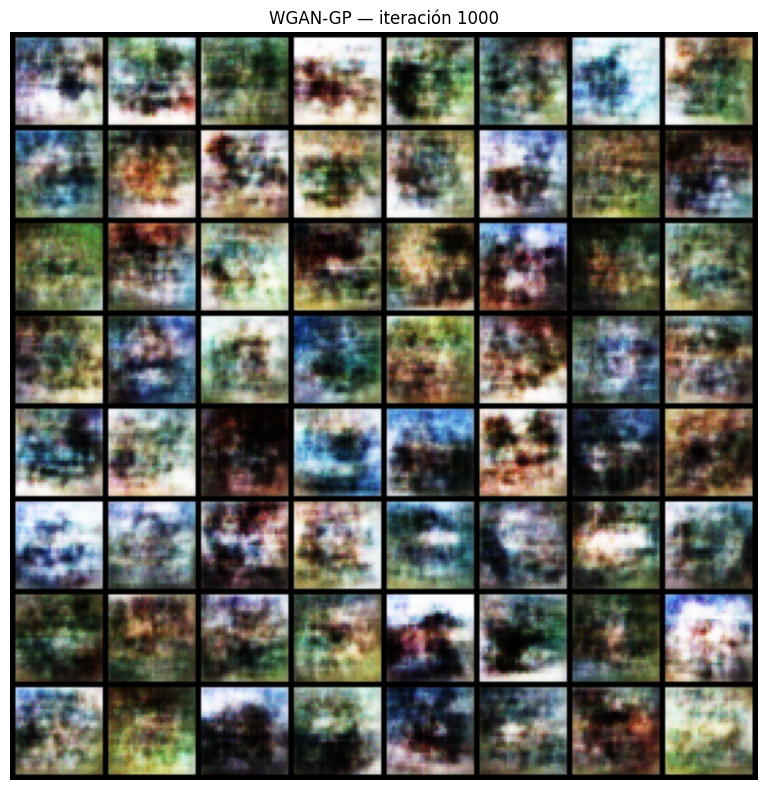

In [ ]:
import os
import torch
import matplotlib.pyplot as plt

from torchvision.utils import make_grid


# ==============================================================
# ITERACIONES QUE QUIERES VISUALIZAR
# ==============================================================

ITERATIONS_TO_SHOW = [
    1000
    # 10000,
    # 100000,
    # 200000,
    # 300000,
]

# Usaremos el mismo ruido en todas las comparaciones.
comparison_noise = None


# ==============================================================
# RECORRER LOS CHECKPOINTS SOLICITADOS
# ==============================================================

for requested_iteration in ITERATIONS_TO_SHOW:

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR_GP,
        f"wgan_gp_iter_{requested_iteration}.pt"
    )

    # Si todavía no existe, avisar y pasar al siguiente.
    if not os.path.exists(checkpoint_path):
        print(
            f"Iteración {requested_iteration}: "
            "checkpoint no disponible."
        )
        continue

    # Cargar en CPU para no ocupar GPU con el crítico
    # y los optimizadores que también contiene el archivo.
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu"
    )

    saved_iteration = checkpoint["iteration"]

    # Crear un generador independiente del que entrenas.
    generator_to_show = Generator(
        latent_dim=checkpoint["z_dim"],
        dim=checkpoint["dim"]
    ).to(device)

    generator_to_show.load_state_dict(
        checkpoint["generator_state_dict"]
    )

    generator_to_show.eval()

    # Recuperar el ruido del primer checkpoint disponible.
    # Reutilizarlo permite comparar las mismas entradas.
    if comparison_noise is None:
        comparison_noise = (
            checkpoint["fixed_noise"]
            .detach()
            .cpu()
            .clone()
        )

    if comparison_noise.shape[1] != checkpoint["z_dim"]:
        raise ValueError(
            "Los checkpoints tienen dimensiones de ruido diferentes."
        )

    # Generar con el lote completo de ruido fijo.
    with torch.no_grad():
        generated_images = generator_to_show(
            comparison_noise.to(device)
        ).cpu()

    # Mostrar hasta 64 imágenes.
    # Conversión de [-1, 1] a [0, 1].
    images_to_show = (
        (generated_images[:64] + 1.0) / 2.0
    ).clamp(0, 1)

    grid = make_grid(
        images_to_show,
        nrow=8,
        padding=2
    )

    # Una cuadrícula por checkpoint.
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.title(f"WGAN-GP — iteración {saved_iteration}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    # Liberar el modelo de evaluación antes del siguiente.
    del generator_to_show
    del checkpoint
    del generated_images

# 5. Evaluation
## 5.1 Generated samples
## 5.2 Loss curves
## 5.3 FID / Inception Score
## 5.4 WGAN vs WGAN-GP